# Filbin et al. 2018 — Pediatric H3-K27M Mutant Glioma (SmartSeq2)
## 01 · Preprocessing → Gate 1 (mixing + continuity)

Malignant cells of H3-K27M diffuse midline glioma follow a developmental hierarchy
(Filbin et al., *Science* 2018): an **OPC-like** cycling progenitor pool differentiating
toward **AC-like** (astrocyte) and **OC-like** (oligodendrocyte) states. This notebook loads
the malignant compartment, derives every tunable choice from *this* dataset, integrates
samples, and judges **Gate 1** on the regenerated embedding + a per-neighbourhood mixing
metric (iLISI) — never a scalar alone.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (2 levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Filbin2018_Brain-3'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# raw input is the leaf matrix dir (folder minus the '-3' attempt suffix, minus 'Data_')
base = name.split('-')[0]                                # 'Filbin2018_Brain'
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| leaf input: Data_' + base)

dataset: Filbin2018_Brain-3 | category: Brain | leaf input: Data_Filbin2018_Brain


In [3]:
# load dataset -> select malignant cells
# SmartSeq2 TPM: passes through the loader unchanged; only log1p is applied.
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| celltypes:', adata.obs.celltype.value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
# published Filbin per-cell scores + cell cycle come through obs as strings -> numeric
for c in ['g2m_score', 'g1s_score', 'opc_like', 'ac_like', 'oc_like']:
    if c in adata.obs: adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce')
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Filbin2018_Brain
Done.
full atlas: (2587, 23686) | celltypes: {'Malignant': 2259, 'Oligodendrocyte': 232, 'Macrophage': 96}
malignant: (2259, 23686) | samples: 6
expression: X max 12.36 (log1p of TPM)


In [4]:
# per-sample malignant counts -> data-driven threshold (C1: derived, not inherited)
# rule: sort counts, take the largest MULTIPLICATIVE gap, cut at its geometric mean.
# premise (C3): a sparse tail separates cleanly from well-sampled tumours.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts :', dict(zip(n.index, n.values.astype(int))))
print('adjacent ratios          :', np.round(ratios, 2))
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geom. mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (dropped the sparse tail)')
adata

sorted per-sample counts : {'MUV05': np.int64(667), 'BCH869': np.int64(489), 'BCH836': np.int64(438), 'MUV10': np.int64(283), 'BCH1126': np.int64(241), 'MUV01': np.int64(141)}
adjacent ratios          : [1.36 1.12 1.55 1.17 1.71]
largest gap 241 -> 141 (ratio 1.71)
derived threshold (geom. mean across the gap) = 184
kept 5/6 samples -> 2118 cells (dropped the sparse tail)


In [5]:
# filter genes -> overdispersed selection (scFates GAM, data-driven) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
# scree elbow sits at ~5-6 PCs, but the eval audit (03/04) flags a low elbow as
# UNDER-POWERING the manifold into a patient-segregated read. Bound to the SmartSeq2
# precedent scale (Venteicher 20, Kurten 20, Puram 40) -> n_pcs = 20.
NPCS = 20
print('n_pcs =', NPCS, '(scree elbow ~5-6 rejected as under-powering; bounded to precedent)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3583 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3583
PC variance% (1-12): [5.1  2.43 1.68 1.46 1.31 0.51 0.45 0.35 0.33 0.29 0.26 0.24]
n_pcs = 20 (scree elbow ~5-6 rejected as under-powering; bounded to precedent)


In [6]:
# integrate samples with Harmony -> choose theta by per-neighbourhood mixing (iLISI).
# iLISI ~= effective # of samples in each cell's 90-NN; higher = better mixed.
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(_ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values))
print(f'iLISI median (of {nsamp} samples): pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v, 2) for k, v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing rises monotonically toward full mixing, no collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

iLISI median (of 5 samples): pre-Harmony 1.00 | sweep {2: np.float64(2.8), 5: np.float64(3.49), 10: np.float64(3.66)}
selected theta = 10 (mixing rises monotonically toward full mixing, no collapse)


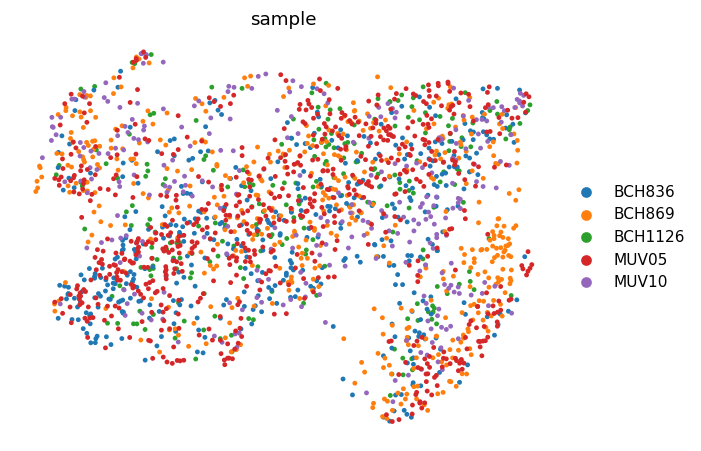

In [7]:
# Gate-1 evidence #1 — the regenerated embedding, coloured by sample (judged on the
# embedding itself, per the eval lesson). Intermixing = integration; archipelago = fail.
sc.pl.umap(adata, color='sample', size=40, frameon=False)

In [8]:
# remove detached islands: UMAP radius-graph (6x median NN), keep the largest component.
# premise (C3): noise detaches cleanly. Complete island removal, then confirm 1 kNN comp.
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
n_island = int((lab != main).sum())
print(f'radius-graph components: {ncomp}; largest = {int((lab==main).sum())} cells')
print('removed', n_island, 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components:', ncc, '(1 = continuous)')

radius-graph components: 1; largest = 2118 cells
removed 0 cells in 0 detached islands
kNN connectivity components: 1 (1 = continuous)


lobe sizes    : {'0': 451, '1': 367, '2': 251, '3': 331, '4': 718}
cell-cycle mix: {'Not cycling': 0.82, 'G1/S': 0.11, 'Intermediate': 0.04, 'G2/M': 0.03}
published Filbin states + G2M by lobe (mean):
  opc_like : {'0': 0.28, '1': -0.01, '2': -0.08, '3': -1.16, '4': 0.35}
  ac_like  : {'0': -0.04, '1': -1.01, '2': -0.64, '3': 2.98, '4': -0.76}
  oc_like  : {'0': 0.13, '1': 0.15, '2': -0.4, '3': -0.29, '4': 0.07}
  g2m_score: {'0': 0.01, '1': 0.08, '2': 1.27, '3': -0.01, '4': 0.04}


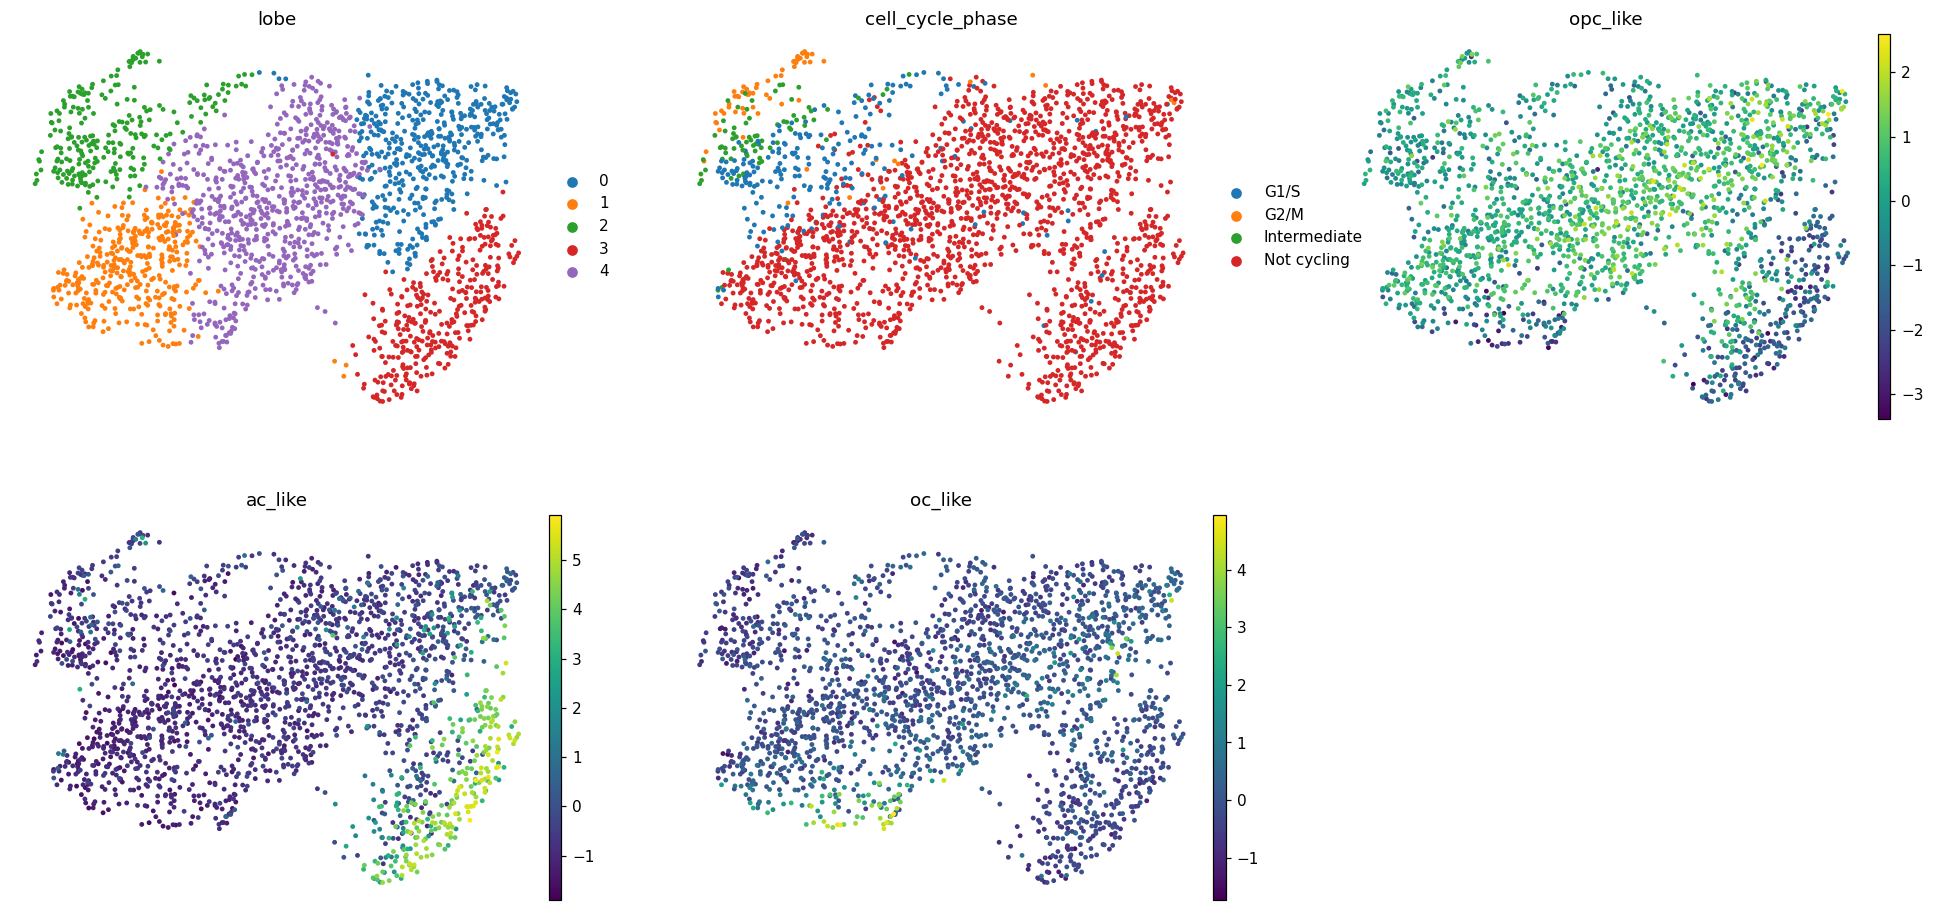

In [9]:
# Gate-1 evidence #2 — sub-region biology BEFORE the GO (Kurten lobe-identity fork).
# coarse Leiden lobes vs published Filbin states + cell cycle: is any lobe a distinct
# lineage, or is one a proliferation confound to be settled in 02?
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = ~adata.obs['cell_cycle_phase'].astype(str).isin(['Not cycling', 'nan'])
print('lobe sizes    :', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cell-cycle mix:', adata.obs['cell_cycle_phase'].value_counts(normalize=True).round(2).to_dict())
print('published Filbin states + G2M by lobe (mean):')
for c in ['opc_like', 'ac_like', 'oc_like', 'g2m_score']:
    print(f'  {c:9s}:', adata.obs.groupby('lobe', observed=True)[c].mean().round(2).to_dict())
sc.pl.umap(adata, color=['lobe', 'cell_cycle_phase', 'opc_like', 'ac_like', 'oc_like'],
           size=40, frameon=False, ncols=3, cmap='viridis')

In [10]:
# orient the embedding to the house convention: rigid rotation onto the major axis,
# developmental origin (Gast/pSom-high) on the LEFT. Distances preserved (X_umap_lin).
# A light Gast/pSom score fixes the sign; deliverable scores are recomputed in 02/03.
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name='_'+lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
origin = (adata.obs['_Gast'] + adata.obs['_pSom']).values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0, 1], vt[0, 0])
Rm = np.array([[np.cos(-th), -np.sin(-th)], [np.sin(-th), np.cos(-th)]])
xyr = c @ Rm.T
if np.average(xyr[:, 0], weights=(origin - origin.min() + 1e-9)) > 0:
    xyr[:, 0] = -xyr[:, 0]                       # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
adata.obs.drop(columns=['_Gast', '_pSom'], inplace=True)
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th):+.1f} deg, origin pole on left -> X_umap_lin')

manifold aspect (max/min std): 1.83
house orientation: rigid rotation +179.6 deg, origin pole on left -> X_umap_lin


In [11]:
# Gate 1 verdict
print(f'{nsamp} samples share ONE continuous manifold (single kNN component; {n_island} island cells);')
print(f'per-neighbourhood iLISI rises {il_pre:.2f} -> {sweep[10]:.2f} of {nsamp} samples under Harmony;')
print('coarse lobes are NOT per-sample: they track the published OPC-like -> AC-like/OC-like')
print('developmental hierarchy. The cycling pocket is a minor fraction, settled in 02 as')
print('orthogonal to the embryonic axis.')
print('Gate 1: mixed + continuous -> GO')

5 samples share ONE continuous manifold (single kNN component; 0 island cells);
per-neighbourhood iLISI rises 1.00 -> 3.66 of 5 samples under Harmony;
coarse lobes are NOT per-sample: they track the published OPC-like -> AC-like/OC-like
developmental hierarchy. The cycling pocket is a minor fraction, settled in 02 as
orthogonal to the embryonic axis.
Gate 1: mixed + continuous -> GO


In [12]:
# tidy obs dtypes -> save processed manifold
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2118, 21106)


saved samples.pdf | cells: 2118


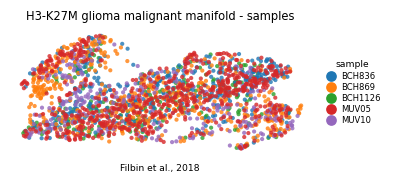

In [13]:
# deliverable: samples.pdf -- house style (3.5,1.5 horizontal strip), house orientation.
# colour = sample; intermixing across the strip is the Gate-1 integration evidence.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('H3-K27M glioma malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])